# Spike Overlap Analysis

This notebook evaluates the overlap between spike protein sequences across different time periods.  
We select a date cutoff to define a **circulating period** before the cutoff, and then compare these sequences with data from the following 12 months.  

The future data is partitioned into:  
- **Contiguous blocks** – consecutive time windows immediately following the cutoff.  
- **Disjoint blocks** – non-overlapping windows within the same 12-month period.  

The analysis reports how much the circulating sequences persist or reappear over time.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# --- Custom imports ---
from Helpers import *   # Contains utility functions for data processing and plotting

# Configure matplotlib for consistent plots
plt.style.use("seaborn-v0_8-whitegrid")

In [2]:
# --- Load spike sequence data ---

# Define the path to the input parquet file
# path = "/data/sukhanna/MPP/ver_2/ver_2A/final_df.parquet"
path = "/data/sukhanna/MPP/ver_2/ver_2A/new_MAT/final_df.parquet"

# Read the parquet file into a DataFrame
final_df = pd.read_parquet(path)

# Quick sanity check: display shape and preview
print(f"Loaded data with {final_df.shape[0]} rows and {final_df.shape[1]} columns")
final_df.head()

Loaded data with 17099263 rows and 4 columns


,Sample_ID,Mutation_ID,Sequence_ID,Date
0,TrinidadandTobago/3851/2020|EPI_ISL_16253526|2...,M_0,S_0,2020-01-01
1,Canada/BC-BCCDC-14740/2020|EPI_ISL_2522133|202...,M_1,S_1,2020-01-01
2,Canada/BC-BCCDC-9093/2020|EPI_ISL_2522107|2020...,M_2,S_2,2020-01-01
3,Wuhan/IVDC-HB-envF54/2020|NMDC60013071-01|2020...,M_3,S_3,2020-01-01
4,Canada/BC-BCCDC-11422/2020|EPI_ISL_2522110|202...,M_2,S_2,2020-01-01


In [3]:
# --- Standardize and validate date column ---

# Find any column containing 'date' (case-insensitive)
date_cols = [col for col in final_df.columns if 'date' in col.lower()]

if not date_cols:
    raise ValueError("No column containing 'date' found in the dataframe.")

# Rename the first matching column to 'Date'
if date_cols[0] != 'Date':
    final_df = final_df.rename(columns={date_cols[0]: 'Date'})

# Ensure 'Date' column is in datetime format
final_df['Date'] = pd.to_datetime(final_df['Date'], format='%Y-%m-%d', errors='coerce')

# Check for any parsing failures (NaT)
if final_df['Date'].isna().any():
    num_invalid = final_df['Date'].isna().sum()
    raise ValueError(f"'Date' column has {num_invalid} entries that could not be parsed as dates.")

# Display confirmation
print(f"'Date' column standardized and validated with {final_df['Date'].nunique()} unique dates.")

'Date' column standardized and validated with 2069 unique dates.


## Demonstration: Processing for a Single Date Cutoff

In this section, we demonstrate the workflow using a single cutoff date.  
This helps to clearly illustrate the data segmentation and overlap analysis steps.  

Later, we will extend this to process multiple cutoff dates in batch.

In [4]:
# --- Define cutoff date ---
cutoff_date = "2022-07-01"

# --- Split dataframe into circulating and future segments ---
current_df, future_df = split_circulating_and_future(
    final_df,
    cutoff_date_str=cutoff_date,
    left_buffer_days=4,
    right_buffer_days=4,
    circulation_months=None,
    circulation_days=15,
    future_months=12,
    future_days=None
)

# --- Define windows for slicing future data ---
disjoint_windows = ['3M_1', '3M_2', '3M_3', '3M_4']

# --- Perform slicing ---
disjoint_slices = slice_by_disjoint_windows(future_df, disjoint_windows)

future_slices = disjoint_slices

# --- Summary output ---
print(f"Disjoint slices: {list(disjoint_slices.keys())}")
print(f"Total future slices stored: {len(future_slices)}")

Disjoint slices: ['3M_1', '3M_2', '3M_3', '3M_4']
Total future slices stored: 4


In [6]:
# --- Compute tip counts for current circulating sequences ---
current_seq_df = (
    current_df.groupby('Sequence_ID')
    .size()
    .reset_index(name='Tip_Count')
    .sort_values(by='Tip_Count', ascending=False)
    .reset_index(drop=True)
)

# --- Compute tip counts for each future window ---
future_seq_dfs = {
    k: (
        v.groupby('Sequence_ID')
        .size()
        .reset_index(name='Tip_Count')
        .sort_values(by='Tip_Count', ascending=False)
        .reset_index(drop=True)
    )
    for k, v in future_slices.items()
}

# --- Summary output ---
print(f"Computed current sequence DataFrame with {len(current_seq_df)} unique sequences")
print(f"Computed future sequence DataFrames for {len(future_seq_dfs)} windows")

Computed current sequence DataFrame with 11520 unique sequences
Computed future sequence DataFrames for 4 windows


In [7]:
summary_stats = compute_summary_stats(current_seq_df, future_seq_dfs, cutoff_key=cutoff_date)

In [8]:
# def pretty_print_stats(summary_stats: Dict[str, Dict[str, pd.DataFrame]]) -> None:
#     """
#     Nicely prints the nested summary stats dictionary.

#     Args:
#         summary_stats (Dict[str, Dict[str, pd.DataFrame]]): Nested stats with [cutoff][period] -> DataFrame
#     """
#     for cutoff, period_dict in summary_stats.items():
#         print(f"\n=== Cutoff: {cutoff} ===")
#         for period, df in period_dict.items():
#             print(f"\n-- {period} --")
#             display(df)  # Use display in notebooks, or print(df.to_string(index=False)) in scripts

In [9]:
pretty_print_stats(summary_stats)


=== Cutoff: 2022-07-01 ===

-- Current --

-- 3M_1 --

-- 3M_2 --

-- 3M_3 --

-- 3M_4 --


## Extending to Multiple Cutoff Dates

We now repeat the above process for a list of cutoff dates, computing statistics for both the circulating and future slices at each timepoint.

In [11]:
# --- List of cutoff dates --- 
# cutoff_dates = [
#     "2020-04-01",
#     "2020-07-01",
#     "2021-01-01",
#     "2021-07-01",
#     "2022-01-01",
#     "2022-07-01",
#     "2023-01-01"
# ]
cutoff_dates = [
    "2022-07-01",
    "2023-07-01",
    "2024-07-01"
]

# --- Windows definitions (reuse for all cutoffs) ---
disjoint_windows = ['3M_1', '3M_2', '3M_3', '3M_4']

# --- Dictionary to hold all results ---
all_summary_stats = {}

for cutoff_date in cutoff_dates:
    # --- Split dataframe into circulating and future segments ---
    current_df, future_df = split_circulating_and_future(
        final_df,
        cutoff_date_str=cutoff_date,
        left_buffer_days=4,
        right_buffer_days=4,
        circulation_months=None,
        circulation_days=30,
        future_months=12,
        future_days=None
    )
    
    # --- Slice future data ---
    disjoint_slices = slice_by_disjoint_windows(future_df, disjoint_windows)
    future_slices = disjoint_slices
    
    # --- Compute tip counts for current circulating sequences ---
    current_seq_df = (
        current_df.groupby('Sequence_ID')
        .size()
        .reset_index(name='Tip_Count')
        .sort_values(by='Tip_Count', ascending=False)
        .reset_index(drop=True)
    )
    
    # --- Compute tip counts for each future window ---
    future_seq_dfs = {
        k: (
            v.groupby('Sequence_ID')
            .size()
            .reset_index(name='Tip_Count')
            .sort_values(by='Tip_Count', ascending=False)
            .reset_index(drop=True)
        )
        for k, v in future_slices.items()
    }
    
    # --- Compute and store summary stats ---
    summary_stats = compute_summary_stats(current_seq_df, future_seq_dfs, cutoff_key=cutoff_date)
    all_summary_stats.update(summary_stats)

In [13]:
all_summary_stats["2022-07-01"]["3M_1"]

,Unique Spike Sequences,Total Tip Count,Number of Seen Spikes,% Tip Count of Seen Spikes
0,37199,1382983,6056,93.9


## Visualizing Sequence Overlap and Tip Coverage Across Cutoff Dates

In this section, we will plot the summary statistics computed for each cutoff date.  
These visualizations will help us understand how the number of unique sequences, tip counts, and their overlaps evolve over time in both circulating and future windows.

In [14]:
import pandas as pd

slice_keys = ['3M_1', '3M_2', '3M_3', '3M_4']

# Initialize the Average dict
all_summary_stats['Average'] = {}

for slice_name in slice_keys:
    # Collect the DataFrames for this slice across all dates
    dfs_to_avg = [all_summary_stats[cutoff][slice_name] 
                  for cutoff in all_summary_stats.keys() if cutoff != 'Average']
    
    # Concatenate along rows
    concatenated = pd.concat(dfs_to_avg, ignore_index=True)
    
    # Average numeric columns
    numeric_cols = concatenated.select_dtypes(include='number').columns
    averaged_row = concatenated[numeric_cols].mean().to_frame().T
    
    # Preserve non-numeric columns (optional, just take the first value)
    non_numeric_cols = [c for c in concatenated.columns if c not in numeric_cols]
    for col in non_numeric_cols:
        averaged_row[col] = concatenated[col].iloc[0]
    
    # Store back in the Average dict
    all_summary_stats['Average'][slice_name] = averaged_row.reset_index(drop=True)

/tmp/ipykernel_761291/1921524501.py:68: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticks(), fontsize=16)


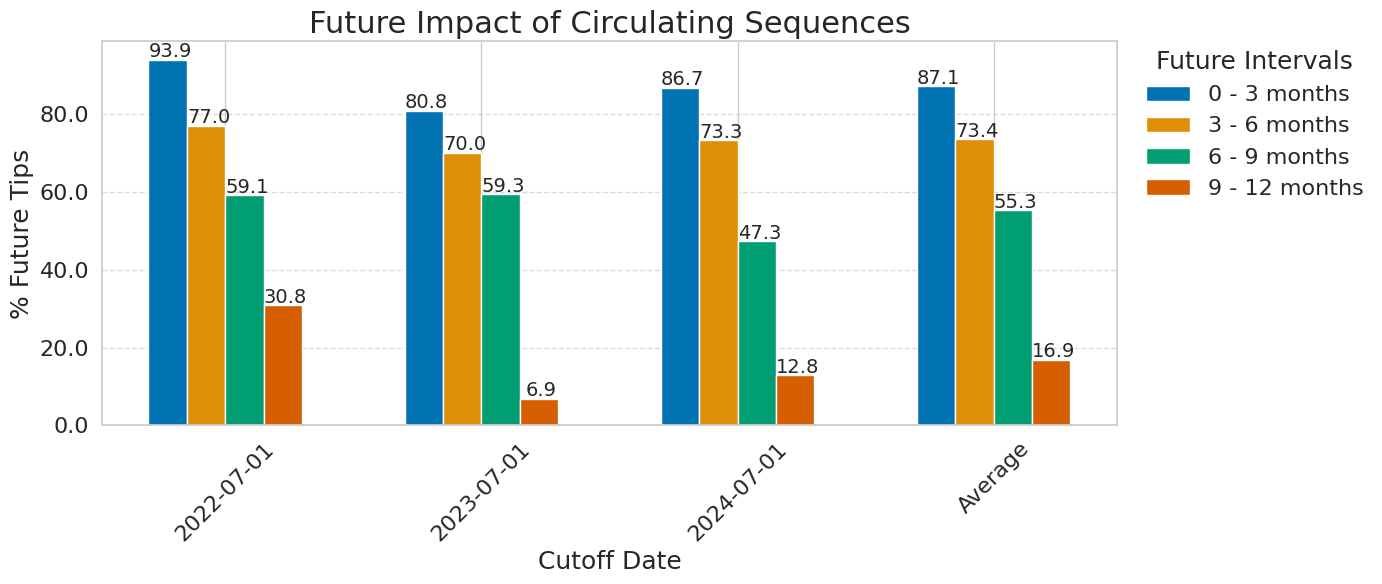

In [26]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# --- Prepare data for plotting ---
cutoffs = cutoff_dates + ["Average"]  # include the Average key
slices_to_plot = disjoint_windows
result_to_plot = "% Tip Count of Seen Spikes"

plot_data = {slice_name: [] for slice_name in slices_to_plot}

for cutoff in cutoffs:
    stats_for_cutoff = all_summary_stats.get(cutoff, {})
    for slice_name in slices_to_plot:
        df = stats_for_cutoff.get(slice_name)
        if df is not None:
            val = df[result_to_plot].values[0]
        else:
            val = 0
        plot_data[slice_name].append(val)

# --- Plot setup with Seaborn style ---
sns.set_theme(style="whitegrid", palette="colorblind")
bar_width = 0.15
x = np.arange(len(cutoffs))

fig, ax = plt.subplots(figsize=(14, 6))  # slightly larger figure

# --- Legend label mapping ---
legend_labels = {
    "3M_1": "0 - 3 months",
    "3M_2": "3 - 6 months",
    "3M_3": "6 - 9 months",
    "3M_4": "9 - 12 months"
}

# Use seaborn color palette
colors = sns.color_palette("colorblind", len(slices_to_plot))

# Plot bars
for i, (slice_name, color) in enumerate(zip(slices_to_plot, colors)):
    bars = ax.bar(
        x + i * bar_width,
        plot_data[slice_name],
        width=bar_width,
        label=legend_labels.get(slice_name, slice_name),
        color=color
    )

    # Annotate only the 1st and 3rd slice (bar) in each cutoff group
    for bar in bars:
        height = bar.get_height()
        ax.annotate(
            f"{height:.1f}",
            xy=(bar.get_x() + bar.get_width() / 2 + 0.01, height - 1.5),
            xytext=(0, 3),
            textcoords="offset points",
            ha="center",
            va="bottom",
            rotation=0,   # angled annotation
            fontsize=14
        )


# --- Final touches ---
ax.set_xticks(x + bar_width * (len(slices_to_plot) - 1) / 2)
ax.set_xticklabels(cutoffs, rotation=45, fontsize=16)
ax.set_yticklabels(ax.get_yticks(), fontsize=16)
ax.set_xlabel("Cutoff Date", fontsize=18)
ax.set_ylabel("% Future Tips", fontsize=18)
ax.set_title("Future Impact of Circulating Sequences", fontsize=22)

ax.legend(
    title="Future Intervals",
    fontsize=16,
    title_fontsize=18,
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    borderaxespad=0
)

ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig("/data/sukhanna/MPP/ver_2/ver_2A/Final_Images/seen_overlap_trend.svg", format="svg")

plt.show()

In [16]:
plot_data

{'3M_1': [90.48, 90.56, 84.57, 90.9, 91.77, 93.66, 84.28, 89.46],
 '3M_2': [83.04, 80.27, 74.02, 83.17, 78.4, 74.38, 51.5, 74.96857142857142],
 '3M_3': [71.7, 65.28, 63.68, 81.26, 68.58, 57.35, 10.47, 59.760000000000005],
 '3M_4': [61.73, 55.53, 54.69, 54.26, 20.54, 31.5, 1.5, 39.964285714285715]}